# stitching

> Gaussian-weighted patch accumulation and output reconstruction.
>
> Takes per-tile model predictions and blends them back into a single
> full-resolution output tensor.  Supports four merge strategies
> (:class:`~segmentation_tools_pt.tiling_core.MergeStrategy`).

In [5]:
#| default_exp stitching

In [6]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
#| hide
from nbdev.showdoc import *

In [87]:
#| export
from __future__ import annotations
from fastcore.all import *
from fastcore.script import *
import matplotlib.pyplot as plt
import numpy as np

import logging
import warnings
from typing import List, Optional, Tuple,Union
import cv2
from pathlib import Path
from fastcore.all import *
from matplotlib import patches

In [12]:
#|  export
import torch
import torch.nn as nn
from torch import Tensor



In [13]:
#| exporti
from segmentation_tools_pt.tiling_core import (
    MergeStrategy, 
    PatchCoords
)
from segmentation_tools_pt.tiling import *


## Weight maps

In [14]:
#| export
def gaussian_weight_map(
    patch_size: int, # Tile side length (assumed square).
    sigma_factor: float = 0.25, # Controls the spread.  Smaller → sharper centre weighting.
    device: Optional[torch.device] = None, # Target device for the returned tensor.
) -> Tensor:
    """Build a 2-D Gaussian weight map of shape ``(patch_size, patch_size)``.

    The Gaussian is centred at the tile centre with
    ``sigma = sigma_factor * patch_size``.  Values are normalised so the
    maximum weight is 1.0.

    Returns:
        Float tensor ``(patch_size, patch_size)`` with values in ``(0, 1]``.

    Example::
        w = gaussian_weight_map(256)
        # w.shape == (256, 256),  w.max() == 1.0
    """
    sigma = sigma_factor * patch_size
    # Build 1-D Gaussian kernel then take outer product
    coords_1d = torch.arange(patch_size, dtype=torch.float32, device=device)
    centre = (patch_size - 1) / 2.0
    gauss_1d = torch.exp(-0.5 * ((coords_1d - centre) / sigma) ** 2)
    weight_map = torch.outer(gauss_1d, gauss_1d)
    weight_map = weight_map / weight_map.max()  # normalise to [0, 1]
    return weight_map

## PatchAccumulator

In [15]:
#| export
class PatchAccumulator:
    """Stateful accumulator that reconstructs a full-resolution output from tile predictions.

    The accumulator maintains two buffers on the target device:

    * ``_sum``   — weighted sum of tile predictions.
    * ``_weight`` — sum of weights (for normalisation).

    Call :meth:`add` for each tile, then :meth:`result` to obtain the
    normalised fused output.


    Example::

        acc  = PatchAccumulator(output_h=H, output_w=W, num_classes=2,
                                strategy=MergeStrategy.GAUSSIAN_WEIGHTED, patch_size=256)
        w    = gaussian_weight_map(256)
        for patch, coord in zip(patches, coords):
            acc.add(patch, coord, weight_map=w)
        output = acc.result()   # (1, 2, H, W)
    """

    def __init__(
        self,
        output_h:             int, # Output canvas height (after padding has been applied).
        output_w:             int, # Output canvas width (after padding has been applied).
        num_classes:          int, # Number of output channels (e.g. segmentation classes).
        strategy:             MergeStrategy = MergeStrategy.GAUSSIAN_WEIGHTED, # Blending strategy.  See :class:`~segmentation_tools_pt.tiling_core.MergeStrategy`.
        patch_size:           int          = 256, # Required when ``strategy`` is ``GAUSSIAN_WEIGHTED``.
        sigma_factor:         float        = 0.25, # Gaussian spread factor (see :func:`gaussian_weight_map`).
        confidence_threshold: float        = 0.5, # Threshold for ``CONFIDENCE_WEIGHTED`` strategy.
        device:               Optional[torch.device] = None, # Target device for accumulation buffers.
    ) -> None:
        self.strategy             = MergeStrategy(strategy)
        self.confidence_threshold = confidence_threshold
        self.device               = device

        self._sum    = torch.zeros((1, num_classes, output_h, output_w), device=device)
        self._weight = torch.zeros((1, 1,           output_h, output_w), device=device)

        # Pre-compute the Gaussian weight map once (reused for every tile)
        if self.strategy == MergeStrategy.GAUSSIAN_WEIGHTED:
            self._gauss = gaussian_weight_map(patch_size, sigma_factor, device=device)
            self._gauss = self._gauss.unsqueeze(0).unsqueeze(0)  # (1,1,P,P)
        else:
            self._gauss = None

    def add(
        self,
        patch: Tensor,# Prediction tensor ``(1, C, patch_size, patch_size)``.
        coords: PatchCoords, # Spatial position of this tile in the canvas.
        weight_map: Optional[Tensor] = None,# Optional explicit weight map ``(1, 1, patch_size, patch_size)``.  If ``None``, the strategy's default map is used.
    ) -> None:
        """Accumulate one tile prediction.

        """
        ys, ye = coords.y_start, coords.y_end
        xs, xe = coords.x_start, coords.x_end

        if self.strategy == MergeStrategy.OVERWRITE:
            self._sum[:, :, ys:ye, xs:xe] = patch
            self._weight[:, :, ys:ye, xs:xe] = 1.0
            return

        if weight_map is not None:
            w = weight_map
        elif self.strategy == MergeStrategy.GAUSSIAN_WEIGHTED:
            w = self._gauss
        elif self.strategy == MergeStrategy.CONFIDENCE_WEIGHTED:
            # Use the maximum softmax score per pixel as the weight
            # TODO(user): patch here is raw logits — apply softmax first
            w = patch.max(dim=1, keepdim=True).values
        else:  # AVERAGE
            w = torch.ones(1, 1, patch.shape[-2], patch.shape[-1], device=self.device)

        self._sum[:, :, ys:ye, xs:xe]    += patch * w
        self._weight[:, :, ys:ye, xs:xe] += w

    def result(self) -> Tensor:
        """Return the weight-normalised fused output.

        Returns:
            Float tensor ``(1, C, H, W)`` with the blended predictions.

        Raises:
            RuntimeError: If any pixel has zero accumulated weight (no tile covered it).
        """
        if (self._weight == 0).any():
            raise RuntimeError(
                "Some canvas pixels have zero weight — every pixel must be "
                "covered by at least one tile.  Check TileConfig.overlap."
            )
        return self._sum / self._weight

## TileMerger — nn.Module wrapper

In [16]:
#| export
class TileMerger(nn.Module):
    """Stateless :class:`torch.nn.Module` that stitches batched tile predictions.

    Intended to be used as a sub-module of
    :class:`~segmentation_tools_pt.model_wrapper.TiledModel`.

    .. note::
        The number of classes (output channels) is inferred lazily from the
        first batch of predictions — no dry-run required.


    .. warning::
        Like :class:`~segmentation_tools_pt.tiling.TileProcessor`, this class
        is **not** directly ONNX-exportable because it accepts a Python list of
        :class:`~segmentation_tools_pt.tiling_core.PatchCoords`.  Use
        :class:`~segmentation_tools_pt.model_wrapper.TiledModel` for ONNX.
    """

    def __init__(
        self,
        patch_size:           int, # Tile side length.
        strategy:             MergeStrategy = MergeStrategy.GAUSSIAN_WEIGHTED, # Blending strategy.
        sigma_factor:         float         = 0.25,# Gaussian spread factor.
        confidence_threshold: float         = 0.5, # Threshold for ``CONFIDENCE_WEIGHTED`` strategy.
    ) -> None:
        super().__init__()
        self.patch_size           = patch_size
        self.strategy             = MergeStrategy(strategy)
        self.sigma_factor         = sigma_factor
        self.confidence_threshold = confidence_threshold

    def forward(
        self,
        patches:     Tensor, # Predictions ``(N, C, patch_size, patch_size)``.
        coords:      List[PatchCoords], # Matching list of tile coordinates.
        output_h:    int, # Canvas height.
        output_w:    int, # Canvas width.
    ) -> Tensor:
        """Stitch ``N`` tile predictions into a full canvas.
        Returns:
            Fused tensor ``(1, C, output_h, output_w)``.
        """
        num_classes = patches.shape[1]
        device      = patches.device

        acc = PatchAccumulator(
            output_h=output_h,
            output_w=output_w,
            num_classes=num_classes,
            strategy=self.strategy,
            patch_size=self.patch_size,
            sigma_factor=self.sigma_factor,
            confidence_threshold=self.confidence_threshold,
            device=device,
        )

        for i, c in enumerate(coords):
            acc.add(patches[i:i+1], c)

        return acc.result()

In [17]:
#| export
import torch.nn.functional as F


## Postprocessing presets

Use :func:`build_postprocessing_pipeline` to turn a simple preset string
(``"light"``, ``"medium"``, ``"heavy"``, ``"none"``) into the internal
pipeline list consumed by :class:`TileMergerONNX`.

In [ ]:
#| export
POSTPROCESSING_PRESETS = {
    "none": [],
    "light": [
        {"operation": "opening", "kernel_size": 3, "iterations": 1},
        {"operation": "closing", "kernel_size": 3, "iterations": 1},
    ],
    "medium": [
        {"operation": "opening", "kernel_size": 5, "iterations": 2},
        {"operation": "closing", "kernel_size": 5, "iterations": 1},
    ],
    "heavy": [
        {"operation": "opening", "kernel_size": 7, "iterations": 3},
        {"operation": "closing", "kernel_size": 7, "iterations": 2},
    ],
}


def build_postprocessing_pipeline(
    postprocessing: str | list | bool | None = "light",
) -> list:
    """Build a postprocessing pipeline from a preset string or custom list.

    Args:
        postprocessing:
            - ``"none"`` / ``"light"`` / ``"medium"`` / ``"heavy"`` — preset
            - ``True`` — alias for ``"light"`` (backward compatible)
            - ``False`` / ``None`` — no postprocessing
            - ``list`` — custom pipeline (dict steps and/or callables)

    Returns:
        Pipeline list ready for ``TileMergerONNX(postprocessing_pipeline=...)``.

    Example::

        pipeline = build_postprocessing_pipeline("medium")
        merger = TileMergerONNX(..., postprocessing_pipeline=pipeline)
    """
    if isinstance(postprocessing, list):
        return postprocessing

    if postprocessing is True:
        postprocessing = "light"
    if postprocessing is False or postprocessing is None:
        return []

    if not isinstance(postprocessing, str):
        raise TypeError(
            f"postprocessing must be str, list, bool, or None; got {type(postprocessing)!r}"
        )

    key = postprocessing.lower()
    if key not in POSTPROCESSING_PRESETS:
        valid = ", ".join(sorted(POSTPROCESSING_PRESETS))
        raise ValueError(
            f"Unknown postprocessing preset {postprocessing!r}. Choose one of: {valid}"
        )

    return list(POSTPROCESSING_PRESETS[key])

In [ ]:
#| export
class TileMergerONNX(nn.Module):
    """
    ONNX opset 12 compatible module for merging overlapping binary mask tiles.
    Fixed positions — no list inputs needed.  All positions pre-computed in
    ``__init__`` so the tracer unrolls the loop into constant-index slice ops.

    If ``input_h`` or ``input_w`` is smaller than ``tile_size``, the padded
    canvas is enlarged to ``tile_size`` so that at least one tile can be merged.

    Postprocessing can be configured three ways:

    1. **Default** (``apply_postprocessing=True``, ``postprocessing_pipeline=None``):
       applies one opening then one closing with ``kernel_size=3``.
    2. **Custom built-in ops** — pass a list of dicts, each with keys
       ``"operation"`` (``"opening"`` or ``"closing"``), ``"kernel_size"``,
       and ``"iterations"``.
    3. **Custom callables** — any step in the list may be a
       ``Callable[[Tensor], Tensor]`` and it will be called directly.

    Example — mix of built-in and custom::

        def my_op(mask: Tensor) -> Tensor:
            return mask  # your logic here

        merger = TileMergerONNX(
            tile_size=256, overlap=32, input_h=1152, input_w=1632,
            postprocessing_pipeline=[
                {"operation": "opening",  "kernel_size": 5, "iterations": 2},
                my_op,
                {"operation": "closing",  "kernel_size": 3, "iterations": 1},
            ],
        )
    """

    def __init__(
        self,
        tile_size: int = 256, # Tile side length (assumed square).
        overlap: int = 32, # Overlap between tiles.
        input_h: int = 1152, # Input image height.
        input_w: int = 1632, # Input image width.
        merge_strategy: str = "confidence_weighted", # Merge strategy.
        sigma_factor: float = 0.25, # Gaussian spread for ``gaussian_weighted`` (sigma = sigma_factor * tile_size).
        confidence_threshold: float = 0.5, # Confidence threshold for merging.
        device: Optional[torch.device] = None, # Target device for accumulation buffers.
        apply_postprocessing: bool = True, # Enable default opening→closing when ``postprocessing_pipeline`` is ``None``.
        postprocessing_pipeline: Optional[list] = None, # Explicit pipeline (list of dicts or callables).  Overrides ``apply_postprocessing`` when provided.
    ):
        super().__init__()
        self.tile_size = tile_size
        self.overlap = overlap
        self.stride = tile_size - overlap
        self.input_h = input_h
        self.input_w = input_w
        self.merge_strategy = merge_strategy
        self.sigma_factor = sigma_factor
        self.confidence_threshold = confidence_threshold
        self.apply_postprocessing = apply_postprocessing
        self.device = device

        # Resolve postprocessing pipeline:
        #   explicit list > apply_postprocessing flag > empty (no-op)
        if postprocessing_pipeline is not None:
            self.postprocessing_pipeline = postprocessing_pipeline
        elif apply_postprocessing:
            self.postprocessing_pipeline = [
                {"operation": "opening", "kernel_size": 3, "iterations": 1},
                {"operation": "closing", "kernel_size": 3, "iterations": 1},
            ]
        else:
            self.postprocessing_pipeline = []

        # Ensure at least one tile even when input < tile_size
        effective_h = max(input_h, tile_size)
        effective_w = max(input_w, tile_size)

        # Pre-compute number of tiles in each dimension
        self.num_tiles_h = max(1, (effective_h - overlap + self.stride - 1) // self.stride)
        self.num_tiles_w = max(1, (effective_w - overlap + self.stride - 1) // self.stride)

        # Pre-compute positions as Python lists (used at trace time)
        self.h_starts_list: list[int] = []
        self.w_starts_list: list[int] = []
        for i in range(self.num_tiles_h):
            for j in range(self.num_tiles_w):
                self.h_starts_list.append(i * self.stride)
                self.w_starts_list.append(j * self.stride)
        self.num_tiles = len(self.h_starts_list)

        # Pre-compute padded dimensions to fit all tiles
        self.padded_h = max(self.num_tiles_h * self.stride + self.overlap, tile_size)
        self.padded_w = max(self.num_tiles_w * self.stride + self.overlap, tile_size)

        # Pre-compute distance weight mask and store as buffer
        weight = self._create_distance_weight_mask(tile_size)
        gauss_weight = self._create_gaussian_weight_mask(tile_size, self.sigma_factor)
        self.register_buffer("distance_weight", weight)
        self.register_buffer("gaussian_weight", gauss_weight)


In [ ]:
#| test
assert build_postprocessing_pipeline("none") == []
assert len(build_postprocessing_pipeline("light")) == 2
assert build_postprocessing_pipeline("medium")[0]["kernel_size"] == 5
assert build_postprocessing_pipeline("heavy")[1]["iterations"] == 2
assert build_postprocessing_pipeline(True) == build_postprocessing_pipeline("light")
assert build_postprocessing_pipeline(False) == []
assert build_postprocessing_pipeline(None) == []

custom = [{"operation": "opening", "kernel_size": 9, "iterations": 1}]
assert build_postprocessing_pipeline(custom) is custom
print("[OK] build_postprocessing_pipeline presets")

In [ ]:
#| export
@patch_to(TileMergerONNX)
def _create_gaussian_weight_mask(
    self,
    tile_size: int,
    sigma_factor: float = 0.25,
) -> Tensor:
    """Create 2D Gaussian weight map, opset 12 compatible. Matches :func:`gaussian_weight_map`."""
    device = self.device
    sigma = sigma_factor * tile_size
    centre = (tile_size - 1) / 2.0
    coords_1d = torch.arange(tile_size, dtype=torch.float32, device=device)

    gauss_1d = torch.exp(-0.5 * ((coords_1d - centre) / sigma) ** 2)
    weight = gauss_1d.unsqueeze(1) * gauss_1d.unsqueeze(0)
    weight = weight / weight.max()
    return weight


In [ ]:
#| export
@patch_to(TileMergerONNX)
def _create_distance_weight_mask(
    self,  # TileMergerONNX instance (unused, but allows access to tile_size if needed)
    tile_size: int, # Tile side length (assumed square).
    ) -> Tensor:
    """Create distance-based weight mask using only opset 12 compatible ops."""
    device = self.device
    y_coords = torch.arange(tile_size, dtype=torch.float32, device=device)
    x_coords = torch.arange(tile_size, dtype=torch.float32, device=device)

    # Manula meshgrid (opset 12 compatible)
    y = y_coords.unsqueeze(1).expand(tile_size, tile_size)
    x = x_coords.unsqueeze(0).expand(tile_size, tile_size)

    # calculate distance from center
    center = tile_size / 2.0 - 0.5
    dx = x - center
    dy = y - center

    # distance calculation using basic operation
    dist_squared = dx * dx + dy * dy
    dist_from_center = torch.sqrt(dist_squared + 1e-8)

    # max distance from center to edge
    max_dist = torch.sqrt(torch.tensor(2.0 * center * center))

    # Convert distance to weight( corner to center)
    weight = 1.0 - (dist_from_center / max_dist)
    weight = torch.clamp(weight, 0.1, 1.0)
    return weight


In [69]:
#| export
@patch_to(TileMergerONNX)
def _morphological_opening(
    self,  
    mask: Tensor,  # Binary mask tensor of shape (1, 1, H, W).
    kernel_size: int = 3, # kernel size for morphological operations (must be odd for symmetric padding).
    iterations: int = 1 # number of times to apply opening operation.
    ) -> Tensor:
    """ONNX opset 12 compatible morphological opening via max/min pooling."""
    padding = kernel_size // 2
    result = mask
    
    for _ in range(iterations):
        # Opening (erosion then dilation)
        eroded = -F.max_pool2d(-result, kernel_size=kernel_size, stride=1, padding=padding)
        result = F.max_pool2d(eroded, kernel_size=kernel_size, stride=1, padding=padding)
    
    return result



In [70]:
#| export
@patch_to(TileMergerONNX)
def _morphological_closing(
    self,  
    mask: Tensor,  # Binary mask tensor of shape (1, 1, H, W).
    kernel_size: int = 3, # kernel size for morphological operations (must be odd for symmetric padding).
    iterations: int = 1 # number of times to apply closing operation.
    ) -> Tensor:
    """ONNX opset 12 compatible morphological closing via max/min pooling."""
    padding = kernel_size // 2
    result = mask
    
    for _ in range(iterations):
        # Closing (dilation then erosion)
        dilated = F.max_pool2d(result, kernel_size=kernel_size, stride=1, padding=padding)
        result = -F.max_pool2d(-dilated, kernel_size=kernel_size, stride=1, padding=padding)
    
    return result

In [ ]:
#| export
@patch_to(TileMergerONNX)
def _forward_overwrite(
    self, 
    tiles: Tensor
    ) -> Tensor:
    """ONNX opset 12: last tile wins in overlap regions."""
    device = tiles.device
    C = tiles.shape[1]
    canvas = torch.zeros(
        1, C, self.padded_h, self.padded_w,
        device=device, dtype=torch.float32)
    for i in range(self.num_tiles):
        start_h = self.h_starts_list[i]
        start_w = self.w_starts_list[i]
        end_h = start_h + self.tile_size
        end_w = start_w + self.tile_size
        canvas[:, :, start_h:end_h, start_w:end_w] = tiles[i : i + 1]
    binary_result = (canvas > self.confidence_threshold).float()
    return binary_result[:, :, : self.input_h, : self.input_w]


In [73]:
#| export
@patch_to(TileMergerONNX)
def _forward_majority_vote(self, tiles: Tensor) -> Tensor:
    """ONNX opset 12: binary vote accumulation, majority wins."""
    device = tiles.device
    C = tiles.shape[1]
    vote_sum = torch.zeros(
        1, C, self.padded_h, self.padded_w,
        device=device, dtype=torch.float32)
    vote_count = torch.zeros(
        1, 1, self.padded_h, self.padded_w,
        device=device, dtype=torch.float32)
    binary_tiles = (tiles > self.confidence_threshold).float()
    for i in range(self.num_tiles):
        start_h = self.h_starts_list[i]
        start_w = self.w_starts_list[i]
        end_h = start_h + self.tile_size
        end_w = start_w + self.tile_size
        vote_sum[:, :, start_h:end_h, start_w:end_w] = (
            vote_sum[:, :, start_h:end_h, start_w:end_w] + binary_tiles[i : i + 1]
        )
        vote_count[:, :, start_h:end_h, start_w:end_w] = (
            vote_count[:, :, start_h:end_h, start_w:end_w] + 1.0
        )
    vote_count = torch.clamp(vote_count, min=1.0)
    vote_ratio = vote_sum / vote_count
    binary_result = (vote_ratio > 0.5).float()
    return binary_result[:, :, : self.input_h, : self.input_w]


In [ ]:
#| export
@patch_to(TileMergerONNX)
def _forward_confidence_weighted(
    self, 
    tiles: Tensor) -> Tensor:
    """ONNX opset 12: distance-from-center * confidence weighting (default, best quality)."""
    device = tiles.device
    C = tiles.shape[1]
    weighted_sum = torch.zeros(
        1, C, self.padded_h, self.padded_w,
        device=device, dtype=torch.float32)
    weight_sum = torch.zeros(
        1, 1, self.padded_h, self.padded_w,
        device=device, dtype=torch.float32)
    distance_expand = self.distance_weight.unsqueeze(0).unsqueeze(0)
    for i in range(self.num_tiles):
        start_h = self.h_starts_list[i]
        start_w = self.w_starts_list[i]
        end_h = start_h + self.tile_size
        end_w = start_w + self.tile_size
        tile = tiles[i : i + 1]
        confidence = torch.abs(tile - 0.5) * 2.0
        combined_weight = distance_expand * (0.5 + confidence)
        weighted_sum[:, :, start_h:end_h, start_w:end_w] = (
            weighted_sum[:, :, start_h:end_h, start_w:end_w] + tile * combined_weight
        )
        weight_sum[:, :, start_h:end_h, start_w:end_w] = (
            weight_sum[:, :, start_h:end_h, start_w:end_w] + combined_weight
        )
    weight_sum = torch.clamp(weight_sum, min=1e-8)
    merged = weighted_sum / weight_sum
    binary_result = (merged > self.confidence_threshold).float()
    return binary_result[:, :, : self.input_h, : self.input_w]


In [75]:
#| export
@patch_to(TileMergerONNX)
def _forward_gaussian_weighted(
    self, 
    tiles: Tensor
    ) -> Tensor:
    """ONNX opset 12: 2D Gaussian center weighting (smooth blend, like U-Net overlap-tile)."""
    device = tiles.device
    C = tiles.shape[1]
    weighted_sum = torch.zeros(
        1, C, self.padded_h, self.padded_w,
        device=device, dtype=torch.float32)
    weight_sum = torch.zeros(
        1, 1, self.padded_h, self.padded_w,
        device=device, dtype=torch.float32)
    gauss_expand = self.gaussian_weight.unsqueeze(0).unsqueeze(0)
    for i in range(self.num_tiles):
        start_h = self.h_starts_list[i]
        start_w = self.w_starts_list[i]
        end_h = start_h + self.tile_size
        end_w = start_w + self.tile_size
        tile = tiles[i : i + 1]
        weighted_sum[:, :, start_h:end_h, start_w:end_w] = (
            weighted_sum[:, :, start_h:end_h, start_w:end_w] + tile * gauss_expand
        )
        weight_sum[:, :, start_h:end_h, start_w:end_w] = (
            weight_sum[:, :, start_h:end_h, start_w:end_w] + gauss_expand
        )
    weight_sum = torch.clamp(weight_sum, min=1e-8)
    merged = weighted_sum / weight_sum
    binary_result = (merged > self.confidence_threshold).float()
    return binary_result[:, :, : self.input_h, : self.input_w]


In [ ]:
#| export
@patch_to(TileMergerONNX)
def _apply_postprocessing_pipeline(
    self,
    mask: Tensor  # Binary mask tensor of shape (1, C, H, W)
    ) -> Tensor:
    """Apply the configured postprocessing pipeline to the binary mask.

    Each step in ``postprocessing_pipeline`` can be:

    * A **dict** with keys ``"operation"`` (``"opening"`` or ``"closing"``),
      ``"kernel_size"`` (int, default 3), and ``"iterations"`` (int, default 1).
    * A **callable** ``(Tensor) -> Tensor`` — called directly with the current
      mask and must return a tensor of the same shape.

    Example — custom pipeline with different kernel sizes and a custom step::

        def clamp_op(mask):
            return mask.clamp(0, 1)

        merger.postprocessing_pipeline = [
            {"operation": "opening",  "kernel_size": 5, "iterations": 2},
            clamp_op,
            {"operation": "closing",  "kernel_size": 3, "iterations": 1},
        ]
    """
    result = mask

    for step in self.postprocessing_pipeline:
        if callable(step):
            result = step(result)
        else:
            operation  = step.get("operation")
            kernel_size = step.get("kernel_size", 3)
            iterations  = step.get("iterations", 1)

            if operation == "opening":
                result = self._morphological_opening(result, kernel_size, iterations)
            elif operation == "closing":
                result = self._morphological_closing(result, kernel_size, iterations)
            else:
                raise ValueError(f"Unsupported postprocessing operation: {operation!r}")

    return result


In [78]:
#| export
@patch_to(TileMergerONNX)
def forward(
    self, 
    tiles: Tensor # Tensor of shape ``[N, C, tile_size, tile_size]`` containing the predicted tiles.
    ) -> Tensor:
    """
    Merge tiles back into full image. Strategy is fixed at init; at trace time
    only the chosen branch executes (ONNX opset 12 compatible).

    Supports: ``overwrite``, ``average``, ``majority_vote``, ``confidence_weighted``.

    Returns:
        Binary mask ``[1, C, input_h, input_w]``
    """
    if self.merge_strategy == "overwrite":
        binary_result = self._forward_overwrite(tiles)
    elif self.merge_strategy == "average":
        binary_result = self._forward_average(tiles)
    elif self.merge_strategy == "confidence_weighted":
        binary_result = self._forward_confidence_weighted(tiles)
    elif self.merge_strategy == "majority_vote":
        binary_result = self._forward_majority_vote(tiles)
    elif self.merge_strategy == "gaussian_weighted":
        binary_result = self._forward_gaussian_weighted(tiles)
    else:
        binary_result = self._forward_confidence_weighted(tiles)

    if hasattr(self, 'postprocessing_pipeline') and self.postprocessing_pipeline:
        binary_result = self._apply_postprocessing_pipeline(binary_result)

    return binary_result




In [ ]:
tile_merger = TileMergerONNX(
    tile_size=256,
    overlap=32,
    input_h=input_h,
    input_w=input_w,
    merge_strategy="confidence_weighted",
    confidence_threshold=0.5,
)
stich_tiles = tile_merger(tiles)
print(f' Stiching tiles shape: {stich_tiles.shape}')


 Stiching tiles shape: torch.Size([1, 1, 1152, 1632])


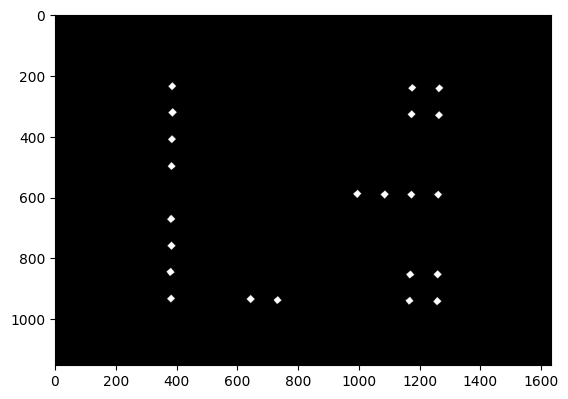

In [58]:
plt.imshow(stich_tiles[0][0].cpu().numpy(), cmap='gray');

 Stiching tiles shape: torch.Size([1, 1, 1152, 1632])


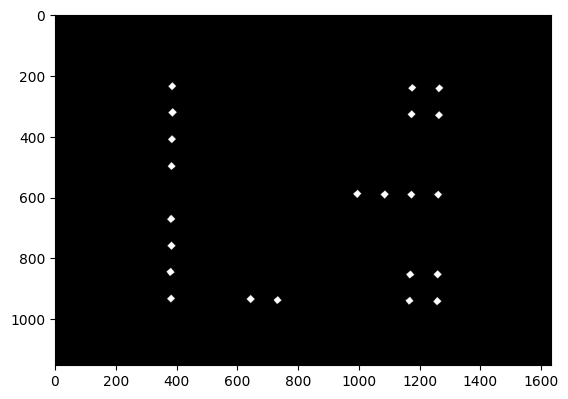

In [80]:
tile_merger = TileMergerONNX(
    tile_size=256,
    overlap=32,
    input_h=input_h,
    input_w=input_w,
    merge_strategy="gaussian_weighted",
    sigma_factor=0.25,
    confidence_threshold=0.5,
)
stich_tiles = tile_merger(tiles)
print(f' Stiching tiles shape: {stich_tiles.shape}')
plt.imshow(stich_tiles[0][0].cpu().numpy(), cmap='gray');


True


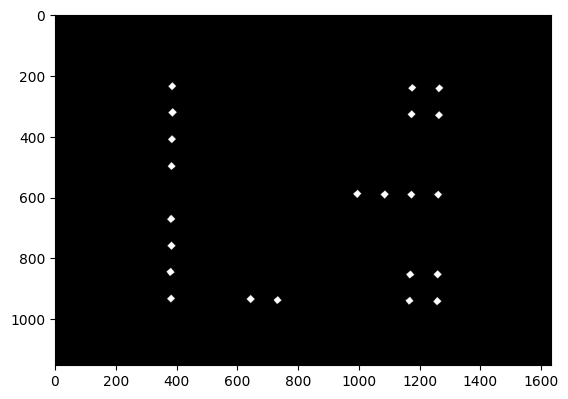

In [27]:
#--- reading ----
msk_path = Path(r"/home/ai_dsx.work/data/projects/goni/hochstrom_pin_ets/1C_Typ150/Incoming/Incoming_unzip/actual_pass_msks")
sm_msk_path = Path(msk_path).ls()[0]
print(sm_msk_path.exists())
sm_msk = cv2.imread(str(sm_msk_path), cv2.IMREAD_GRAYSCALE)

plt.imshow(sm_msk, cmap='gray');

----
#### Mask testing

In [81]:
np.max(sm_msk)

np.uint8(255)

In [32]:
# Normally we get masks as tiles from models, we assumes we get 
# batch of masks after model prediction,so we need to stitch them
msk_tnsr = torch.from_numpy(sm_msk).unsqueeze(0).unsqueeze(0)/255.0
msk_tnsr.max()
msk_tnsr.max(), msk_tnsr.min()

(tensor(1.), tensor(0.))

In [33]:
input_h, input_w= sm_msk.shape[:2]
input_h, input_w

(1152, 1632)

In [ ]:
from segmentation_tools_pt.tiling import *
tile_processor_onnx = TileProcessorONNX(
    tile_size=256,
    overlap=32,
    input_h=input_h,
    input_w=input_w,
)

tiles = tile_processor_onnx(msk_tnsr)
tile_positions = tile_processor_onnx.positions
tiles.shape

torch.Size([40, 1, 256, 256])

In [82]:
tile_merger_onnx = TileMergerONNX(
    tile_size=256,
    overlap=32,
    input_h=input_h,
    input_w=input_w,
    merge_strategy="confidence_weighted",
    confidence_threshold=0.5,
    #apply_postprocessing=True,
)
stich_tiles = tile_merger_onnx(tiles,)
stich_tiles.shape, stich_tiles.min(), stich_tiles.max()

(torch.Size([1, 1, 1152, 1632]), tensor(0.), tensor(1.))

In [83]:
#| export
def visualize_tile_overlay(
    original_image: np.ndarray, # Original image as numpy array [H, W] or [H, W, C]
    tiles: Union[torch.Tensor, np.ndarray], # Tensor or array of tiles [N, C, tile_size, tile_size] or [N, tile_size, tile_size]
    positions: List[Tuple], # List of (row, col, start_h, start_w) for each tile
    tile_size: int = 256, # Size of each tile
    overlap: int = 32, # Overlap between tiles
    figsize: Tuple[int, int] = (20, 15), # Figure size for the plot
    save_path: Optional[Union[str, Path]] = None, # Path to save the visualization
    show_grid: bool = True, # Whether to show grid lines
    alpha: float = 0.3, # Transparency for overlay
    colormap: str = 'tab20' # Colormap for different tiles
) -> None:
    """
    Visualize how tiles overlay on the original image with comprehensive display.
    
    """
    
    # Convert tensors to numpy if needed
    if isinstance(tiles, torch.Tensor):
        tiles = tiles.cpu().numpy()
    
    # Handle different image formats
    if len(original_image.shape) == 3 and original_image.shape[2] == 3:
        display_image = original_image
    elif len(original_image.shape) == 3 and original_image.shape[2] == 1:
        display_image = original_image.squeeze(-1)
    else:
        display_image = original_image
    
    # Create figure with subplots
    fig = plt.figure(figsize=figsize)
    
    # Main layout: 2x2 grid
    gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], width_ratios=[2, 1])
    
    # 1. Original image with tile boundaries
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.imshow(display_image, cmap='gray' if len(display_image.shape) == 2 else None)
    ax1.set_title(f'Original Image with Tile Boundaries\n({len(positions)} tiles, size={tile_size}, overlap={overlap})', 
                  fontsize=14, fontweight='bold')
    
    # Create colormap for tiles
    colors = plt.colormaps.get_cmap(colormap)(np.linspace(0, 1, len(positions)))
    
    # Draw tile boundaries
    for i, (row, col, start_h, start_w) in enumerate(positions):
        rect = patches.Rectangle(
            (start_w, start_h), tile_size, tile_size,
            linewidth=2, edgecolor=colors[i], facecolor=colors[i], alpha=alpha,
            label=f'Tile {i}'
        )
        ax1.add_patch(rect)
        
        # Add tile number in center
        center_x = start_w + tile_size // 2
        center_y = start_h + tile_size // 2
        ax1.text(center_x, center_y, str(i), 
                ha='center', va='center', fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    
    if show_grid:
        ax1.grid(True, alpha=0.3)
    ax1.set_xlabel('Width (pixels)')
    ax1.set_ylabel('Height (pixels)')
    
    # 2. Tile positions heatmap
    ax2 = fig.add_subplot(gs[0, 1])
    tile_count_map = np.zeros_like(display_image[:, :, 0] if len(display_image.shape) == 3 else display_image)
    
    for i, (row, col, start_h, start_w) in enumerate(positions):
        end_h = min(start_h + tile_size, tile_count_map.shape[0])
        end_w = min(start_w + tile_size, tile_count_map.shape[1])
        tile_count_map[start_h:end_h, start_w:end_w] += 1
    
    im2 = ax2.imshow(tile_count_map, cmap='hot', interpolation='nearest')
    ax2.set_title('Tile Overlap Heatmap\n(Darker = More Overlap)', fontsize=12, fontweight='bold')
    plt.colorbar(im2, ax=ax2, label='Number of Overlapping Tiles')
    ax2.set_xlabel('Width (pixels)')
    ax2.set_ylabel('Height (pixels)')
    
    # 3. Sample tiles grid
    ax3 = fig.add_subplot(gs[1, :])
    n_sample_tiles = min(8, len(tiles))  # Show up to 8 sample tiles
    sample_indices = np.linspace(0, len(tiles)-1, n_sample_tiles, dtype=int)
    
    for idx, tile_idx in enumerate(sample_indices):
        ax_tile = plt.subplot(2, n_sample_tiles, n_sample_tiles + idx + 1)
        
        # Handle different tile formats
        if len(tiles[tile_idx].shape) == 3:
            tile_img = tiles[tile_idx][0] if tiles[tile_idx].shape[0] == 1 else tiles[tile_idx]
        else:
            tile_img = tiles[tile_idx]
        
        ax_tile.imshow(tile_img, cmap='gray')
        ax_tile.set_title(f'Tile {tile_idx}', fontsize=10)
        ax_tile.axis('off')
        
        # Add position info
        if tile_idx < len(positions):
            row, col, start_h, start_w = positions[tile_idx]
            ax_tile.text(0.5, -0.1, f'Pos: ({start_h},{start_w})', 
                        transform=ax_tile.transAxes, ha='center', fontsize=8)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Tile overlay visualization saved to: {save_path}")
    
    plt.show()

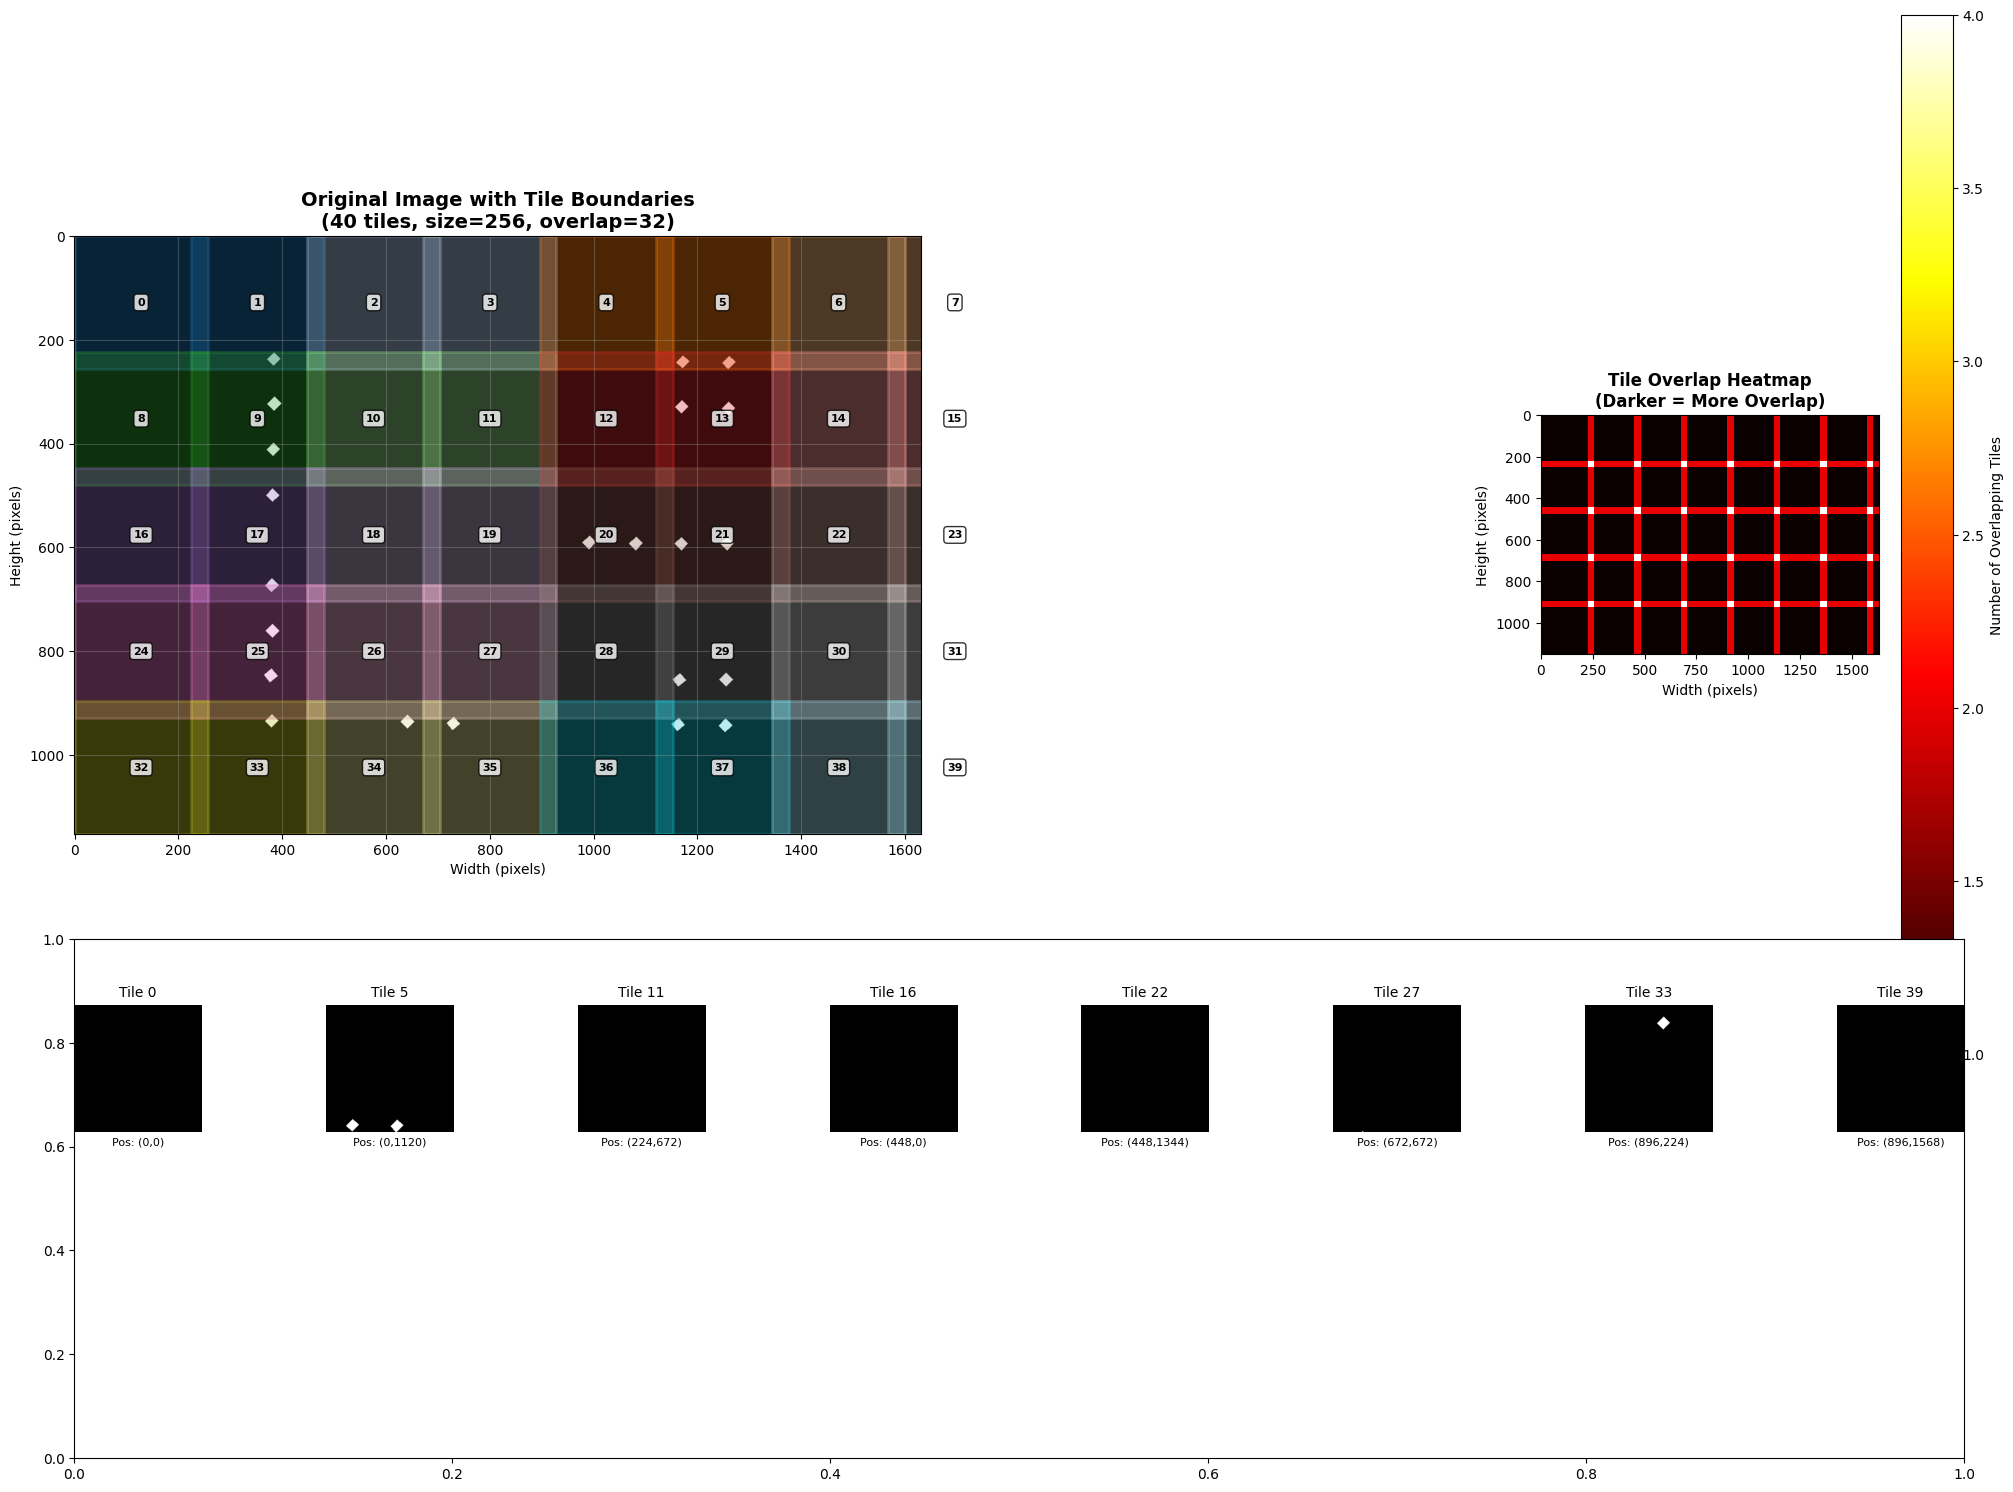

In [88]:
visualize_tile_overlay(
    sm_msk,
    tiles,
    tile_positions,
    tile_size=256,
    overlap=32,
)

In [155]:
#| export
def visualize_tile_mask_overlay(
    original_image: np.ndarray, # Original image as numpy array [H, W] or [H, W, C]
    tiles: Union[torch.Tensor, np.ndarray], # Tensor or array of tiles [N, C, tile_size, tile_size]
    tile_masks: Union[torch.Tensor, np.ndarray], # Predicted masks for each tile [N, C, tile_size, tile_size] or [N, tile_size, tile_size]
    positions: List[Tuple], # List of (row, col, start_h, start_w) for each tile
    tile_size: int = 256, # Size of each tile
    overlap: int = 32, # Overlap between tiles
    mask_threshold: float = 0.5, # Threshold for binary mask visualization
    figsize: Tuple[int, int] = (20, 15), # Figure size for the plot
    save_path: Optional[Union[str, Path]] = None, # Path to save the visualization
    alpha: float = 0.6, # Transparency for mask overlay
    mask_color: str = 'red', # Color for mask overlay ('red', 'green', 'blue', 'yellow', etc.)
    show_confidence: bool = True # Whether to show confidence values as intensity
) -> None:
    """
    Visualize mask predictions for each tile overlaid on the original image.
    
    """
    # Suppress matplotlib font glyph warnings (e.g. missing emoji in monospace)
    warnings.filterwarnings('ignore', message='.*Glyph.*missing from font.*', category=UserWarning)
    
    # Convert tensors to numpy if needed
    if isinstance(original_image, torch.Tensor):
        original_image = original_image.squeeze().cpu().numpy()
    if isinstance(tiles, torch.Tensor):
        tiles = tiles.cpu().numpy()
    if isinstance(tile_masks, torch.Tensor):
        tile_masks = tile_masks.cpu().numpy()
    
    # Handle different image formats
    if len(original_image.shape) == 3 and original_image.shape[2] == 3:
        display_image = original_image.copy()
    elif len(original_image.shape) == 3 and original_image.shape[2] == 1:
        display_image = np.repeat(original_image, 3, axis=2)
    else:
        display_image = np.stack([original_image] * 3, axis=2)
    
    # Ensure display_image is uint8
    if display_image.dtype != np.uint8:
        display_image = (display_image * 255).astype(np.uint8) if display_image.max() <= 1 else display_image.astype(np.uint8)
    
    # Handle different mask formats
    if len(tile_masks.shape) == 4 and tile_masks.shape[1] == 1:
        tile_masks = tile_masks[:, 0]  # Remove channel dimension if single channel
    elif len(tile_masks.shape) == 4:
        tile_masks = tile_masks[:, 0]  # Take first channel if multiple
    
    # Create figure with subplots
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(2, 3, height_ratios=[2, 1], width_ratios=[2, 1, 1])
    
    # 1. Original image with tile mask overlays
    ax1 = fig.add_subplot(gs[0, 0])
    overlay_image = display_image.copy()
    
    # Color mapping for masks
    color_map = {
        'red': [255, 0, 0],
        'green': [0, 255, 0],
        'blue': [0, 0, 255],
        'yellow': [255, 255, 0],
        'cyan': [0, 255, 255],
        'magenta': [255, 0, 255]
    }
    mask_rgb = color_map.get(mask_color, [255, 0, 0])
    
    # Create combined mask overlay
    combined_mask = np.zeros(display_image.shape[:2], dtype=np.float32)
    confidence_map = np.zeros(display_image.shape[:2], dtype=np.float32)
    count_map = np.zeros(display_image.shape[:2], dtype=np.float32)
    
    for i, (row, col, start_h, start_w) in enumerate(positions):
        end_h = min(start_h + tile_size, display_image.shape[0])
        end_w = min(start_w + tile_size, display_image.shape[1])
        
        # Get tile mask
        tile_mask = tile_masks[i]
        
        # Resize mask if needed (skip tiles outside image bounds - avoids cv2.resize error)
        actual_h = end_h - start_h
        actual_w = end_w - start_w
        if actual_h <= 0 or actual_w <= 0:
            continue
        if tile_mask.shape != (actual_h, actual_w):
            tile_mask = cv2.resize(tile_mask.astype(np.float32), (actual_w, actual_h))
        
        # Add to combined mask
        if show_confidence:
            combined_mask[start_h:end_h, start_w:end_w] += tile_mask
            confidence_map[start_h:end_h, start_w:end_w] += tile_mask
        else:
            combined_mask[start_h:end_h, start_w:end_w] += (tile_mask > mask_threshold).astype(np.float32)
        
        count_map[start_h:end_h, start_w:end_w] += 1
    
    # Average overlapping regions
    count_map = np.maximum(count_map, 1)
    combined_mask = combined_mask / count_map
    
    if show_confidence:
        confidence_map = confidence_map / count_map
        # Use confidence as alpha
        mask_alpha = np.clip(confidence_map * alpha, 0, 1)
    else:
        # Binary mask
        combined_mask = (combined_mask > mask_threshold).astype(np.float32)
        mask_alpha = combined_mask * alpha
    
    # Apply mask overlay
    for c in range(3):
        overlay_image[:, :, c] = (
            overlay_image[:, :, c] * (1 - mask_alpha) + 
            mask_rgb[c] * mask_alpha
        ).astype(np.uint8)
    
    ax1.imshow(overlay_image)
    ax1.set_title(f'Original Image with Tile Mask Overlays\n({len(positions)} tiles, threshold={mask_threshold:.2f})', 
                  fontsize=14, fontweight='bold')
    ax1.set_xlabel('Width (pixels)')
    ax1.set_ylabel('Height (pixels)')
    
    # Add tile boundaries
    for i, (row, col, start_h, start_w) in enumerate(positions):
        rect = patches.Rectangle(
            (start_w, start_h), tile_size, tile_size,
            linewidth=1, edgecolor='white', facecolor='none', alpha=0.5
        )
        ax1.add_patch(rect)
    
    # 2. Confidence/probability heatmap
    ax2 = fig.add_subplot(gs[0, 1])
    if show_confidence:
        im2 = ax2.imshow(confidence_map, cmap='hot', vmin=0, vmax=1)
        ax2.set_title('Mask Confidence Heatmap', fontsize=12, fontweight='bold')
        plt.colorbar(im2, ax=ax2, label='Confidence')
    else:
        im2 = ax2.imshow(combined_mask, cmap='gray', vmin=0, vmax=1)
        ax2.set_title('Binary Mask', fontsize=12, fontweight='bold')
        plt.colorbar(im2, ax=ax2, label='Mask Value')
    
    ax2.set_xlabel('Width (pixels)')
    ax2.set_ylabel('Height (pixels)')
    
    # 3. Statistics
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.axis('off')
    
    # Calculate statistics
    total_pixels = combined_mask.size
    if show_confidence:
        high_conf_pixels = np.sum(confidence_map > 0.7)
        med_conf_pixels = np.sum((confidence_map > 0.3) & (confidence_map <= 0.7))
        low_conf_pixels = np.sum(confidence_map <= 0.3)
        avg_confidence = np.mean(confidence_map)
        max_confidence = np.max(confidence_map)
    else:
        mask_pixels = np.sum(combined_mask > mask_threshold)
        mask_percentage = (mask_pixels / total_pixels) * 100
    
    overlap_pixels = np.sum(count_map > 1)
    overlap_percentage = (overlap_pixels / total_pixels) * 100
    
    if show_confidence:
        stats_text = f"""
Mask Statistics:

Confidence Distribution:
High (>0.7): {high_conf_pixels:,} pixels
Medium (0.3-0.7): {med_conf_pixels:,} pixels  
Low (<0.3): {low_conf_pixels:,} pixels

Confidence Metrics:
Average: {avg_confidence:.3f}
Maximum: {max_confidence:.3f}

Overlap Info:
Overlapping: {overlap_pixels:,} pixels
Overlap %: {overlap_percentage:.1f}%

Visualization:
Threshold: {mask_threshold:.2f}
Alpha: {alpha:.2f}
Color: {mask_color}
        """
    else:
        stats_text = f"""
Mask Statistics:

Binary Mask:
Mask Pixels: {mask_pixels:,}
Total Pixels: {total_pixels:,}
Coverage: {mask_percentage:.1f}%

Overlap Info:
Overlapping: {overlap_pixels:,} pixels
Overlap %: {overlap_percentage:.1f}%

Visualization:
Threshold: {mask_threshold:.2f}
Alpha: {alpha:.2f}
Color: {mask_color}
        """
    
    ax3.text(0.05, 0.95, stats_text, transform=ax3.transAxes, 
             fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgray', alpha=0.8))
    
    # 4. Sample tile masks (show tiles that have masks; rank by same criterion as visualization)
    ax4 = fig.add_subplot(gs[1, :])
    n_sample_tiles = min(6, len(tiles))
    # Rank tiles by mask presence: use same metric as display (threshold or mean confidence)
    mask_scores = np.array([
        np.mean(tile_masks[i] > mask_threshold) if not show_confidence else np.mean(tile_masks[i])
        for i in range(len(tile_masks))
    ])
    # Take tiles with highest mask content; if all empty, fallback to evenly spaced
    if mask_scores.max() > 0:
        sample_indices = np.argsort(mask_scores)[::-1][:n_sample_tiles]
    else:
        sample_indices = np.linspace(0, len(tiles)-1, n_sample_tiles, dtype=int)
    
    for idx, tile_idx in enumerate(sample_indices):
        ax_tile = plt.subplot(2, n_sample_tiles, n_sample_tiles + idx + 1)
        
        # Show tile with mask overlay
        if len(tiles[tile_idx].shape) == 3:
            tile_img = tiles[tile_idx][0] if tiles[tile_idx].shape[0] == 1 else tiles[tile_idx]
        else:
            tile_img = tiles[tile_idx]
        
        # Convert tile to RGB if needed
        if len(tile_img.shape) == 2:
            tile_display = np.stack([tile_img] * 3, axis=2)
        else:
            tile_display = tile_img
        
        # Normalize tile image
        if tile_display.max() <= 1:
            tile_display = (tile_display * 255).astype(np.uint8)
        else:
            tile_display = tile_display.astype(np.uint8)
        
        # Overlay mask on tile
        tile_mask = tile_masks[tile_idx]
        if show_confidence:
            mask_alpha_tile = np.clip(tile_mask * alpha, 0, 1)
        else:
            mask_alpha_tile = (tile_mask > mask_threshold).astype(np.float32) * alpha
        
        tile_overlay = tile_display.copy()
        for c in range(3):
            tile_overlay[:, :, c] = (
                tile_overlay[:, :, c] * (1 - mask_alpha_tile) + 
                mask_rgb[c] * mask_alpha_tile
            ).astype(np.uint8)
        
        ax_tile.imshow(tile_overlay)
        
        # Add title with statistics
        if show_confidence:
            avg_conf = np.mean(tile_mask)
            max_conf = np.max(tile_mask)
            title = f'Tile {tile_idx}\nAvg: {avg_conf:.2f}, Max: {max_conf:.2f}'
        else:
            mask_ratio = np.mean(tile_mask > mask_threshold)
            title = f'Tile {tile_idx}\nMask: {mask_ratio:.1%}'
        
        ax_tile.set_title(title, fontsize=9)
        ax_tile.axis('off')
        
        # Add position info
        if tile_idx < len(positions):
            row, col, start_h, start_w = positions[tile_idx]
            ax_tile.text(0.5, -0.15, f'Pos: ({start_h},{start_w})', 
                        transform=ax_tile.transAxes, ha='center', fontsize=8)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Tile mask overlay visualization saved to: {save_path}")
    
    plt.show()


In [156]:
sm_msk_path
sm_im_path = Path(Path(sm_msk_path).parent.parent, 'main_im2_cropped')
im_name = Path(sm_msk_path).name
sm_im_path_ = Path(sm_im_path, im_name)
sm_img_o = cv2.imread(str(sm_im_path_), cv2.IMREAD_GRAYSCALE)
sm_img_t = torch.from_numpy(sm_img_o).unsqueeze(0).unsqueeze(0).float() / 255.0
sm_img_t.shape

torch.Size([1, 1, 1152, 1632])

In [ ]:

im_processor = TileProcessorONNX(
    tile_size=256, 
    overlap=32,
    input_h=1152,
    input_w=1632,
    )
img_tiles = im_processor(sm_img_t)
tile_pos = im_processor.positions
img_tiles.shape


torch.Size([40, 1, 256, 256])

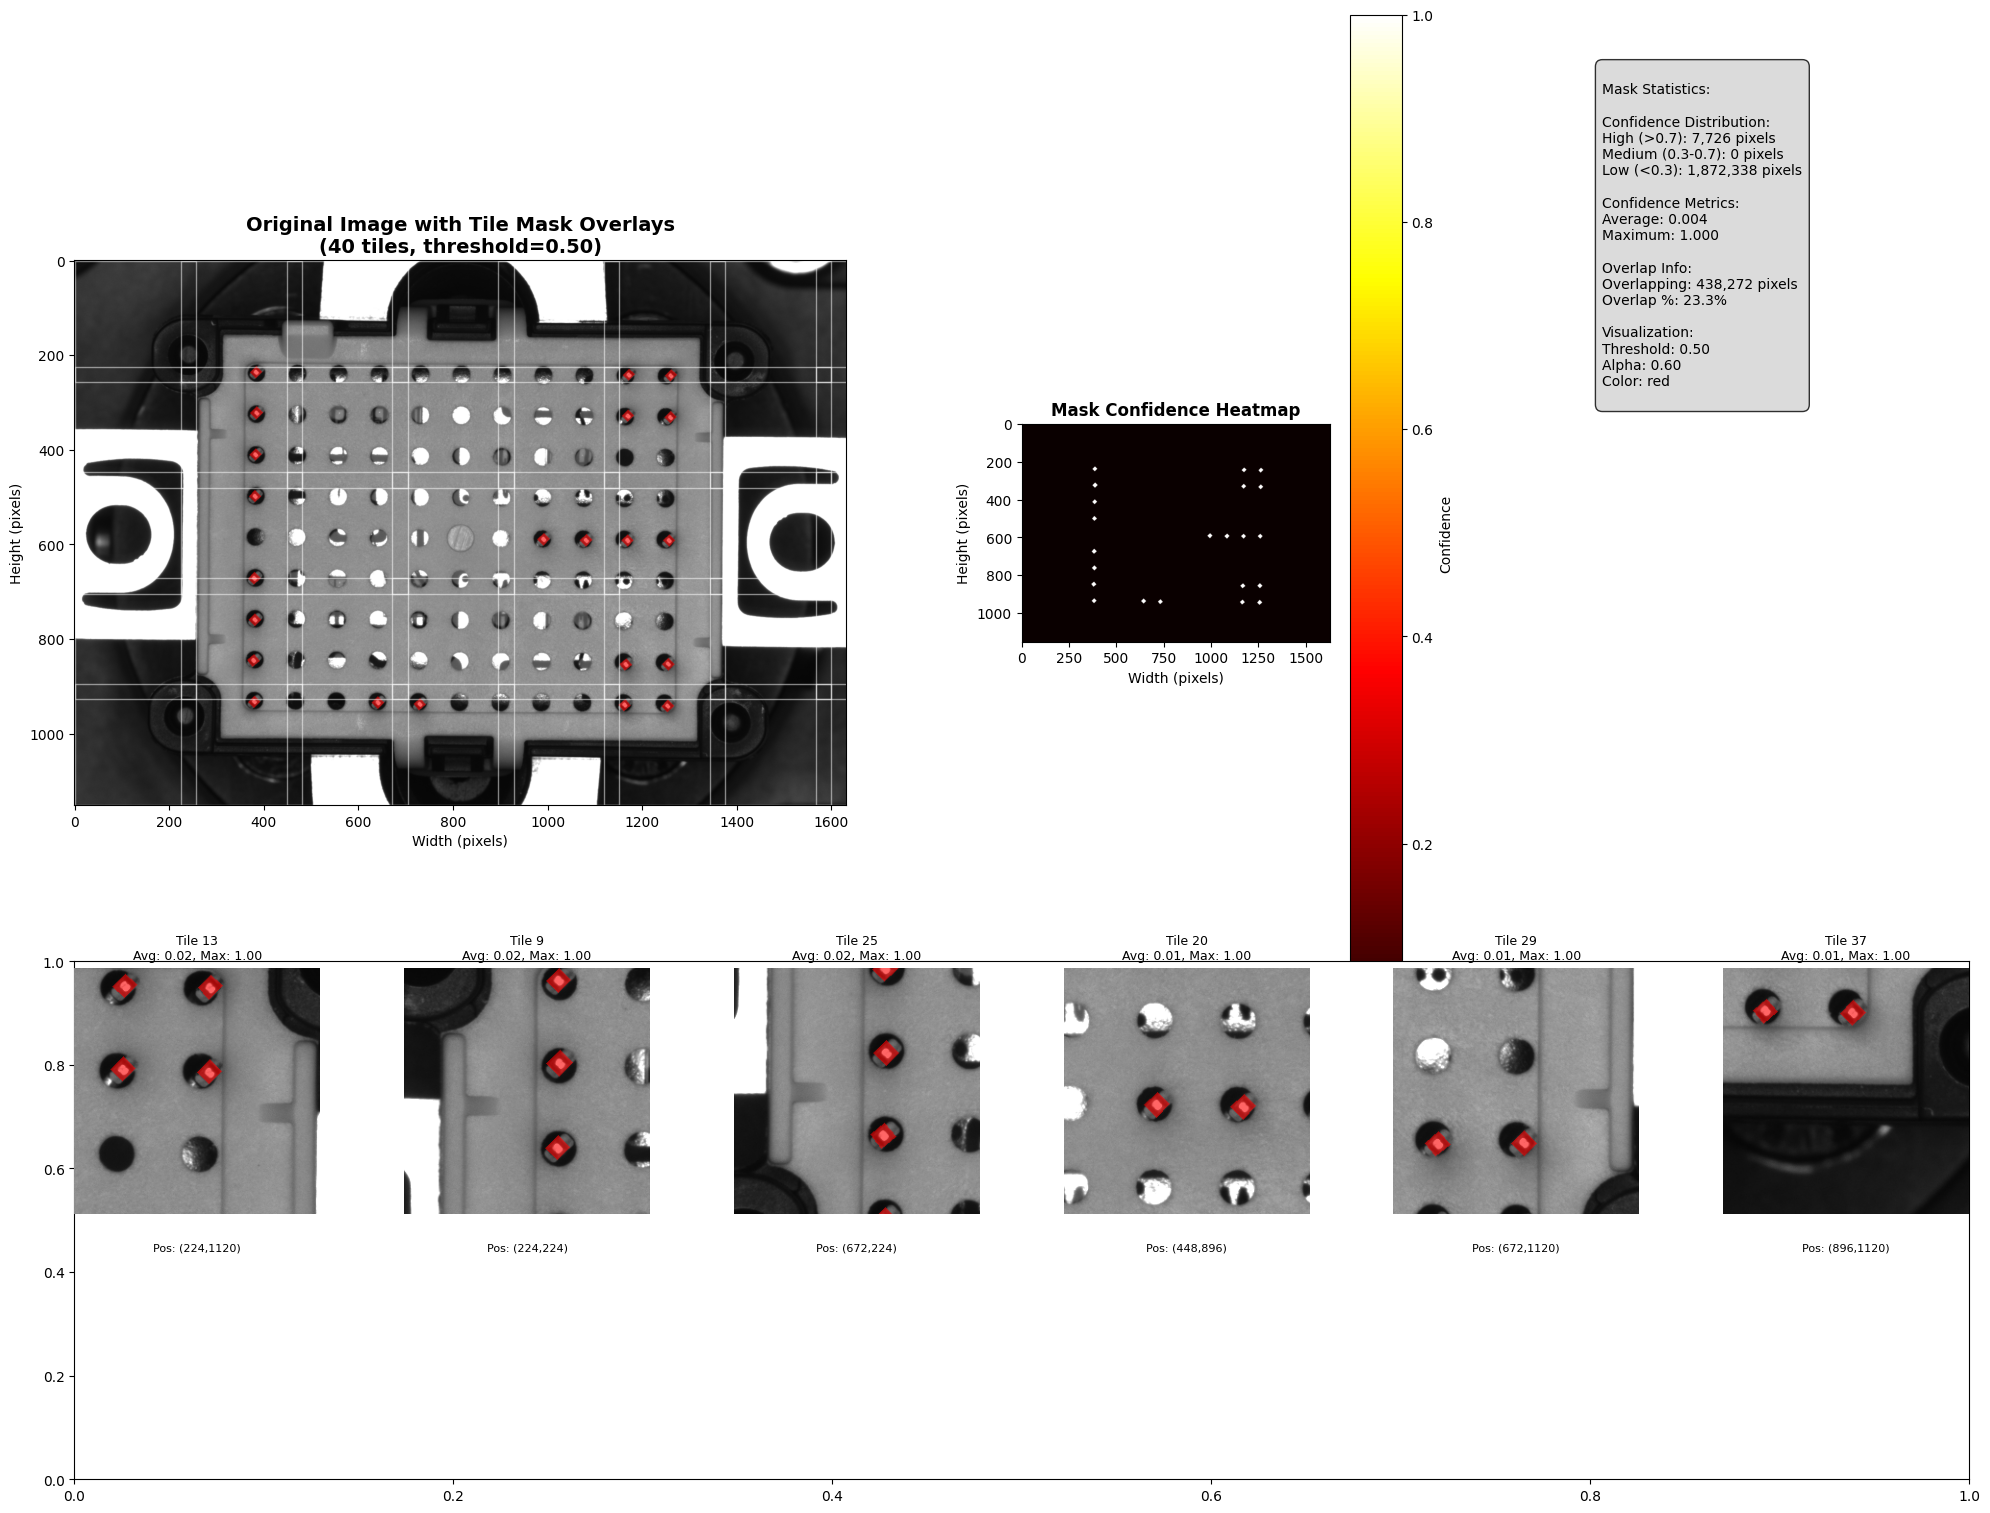

In [159]:
visualize_tile_mask_overlay(
    original_image=sm_img_o,
    tiles=img_tiles,
    tile_masks=tiles,
    positions=tile_pos,
    tile_size=256,
    overlap=32,
    mask_threshold=0.5,
    figsize=(20, 15),
    save_path=None,
    alpha=0.6,
    mask_color='red',
    show_confidence=True
)

## Expert Panel Recommendation: Merging Strategy for Binary Masks

**TL;DR: Use Confidence-Weighted + Distance-from-Center blending (`TileMergerONNX` default).**

### Why? Consensus from image segmentation literature:

1. **Ronneberger et al. (2015, U-Net)** introduced overlap-tile strategy with
   Gaussian weighting. This is the foundation of tile-based segmentation inference.

2. **For binary masks specifically**, the critical insight is:
   - **Never merge hard binary masks directly** — always merge soft probabilities, then threshold
   - Tile **edge pixels are less reliable** (the model sees less spatial context near borders)
   - **Confidence weighting** (`|pred - 0.5| × 2`) naturally handles uncertain pixels near 0.5
   - **Distance-from-center weighting** downweights edges where predictions degrade

3. **Strategy ranking for binary masks** (this library):

| Rank | Strategy | Pros | Cons |
|------|----------|------|------|
| 1 | `confidence_weighted` + distance (`TileMergerONNX`) | Best seam quality, handles ambiguity | Slightly more compute |
| 2 | `gaussian_weighted` | Smooth blending, well-studied | Ignores prediction confidence |
| 3 | `average` | Simple, no center-bias artifacts | Equal weight to poor edge predictions |
| 4 | `overwrite` | Fastest | Visible seams, worst quality |

### The golden rule:
> **Merge soft predictions → threshold → post-process (morphological open/close)**
>
> This is exactly what `TileMergerONNX.forward()` does — and why it is the recommended path.

Below we verify this experimentally with synthetic binary masks,
then consolidate the exploration into reusable functions.

In [109]:
#| export
def plot_weight_maps(
    patch_size: int = 256,  # Tile side length for weight map visualization.
    sigma_factor: float = 0.25,  # Gaussian spread factor.
    figsize: tuple = (15, 4),  # Figure size (width, height) in inches.
) -> None:
    """Plot Gaussian, distance-from-center, and uniform weight maps side by side.

    Useful for understanding how different blending strategies weight
    the centre vs edges of each tile during overlap merging.

    Example::

        plot_weight_maps(patch_size=256)
    """
    import matplotlib.pyplot as plt

    gauss = gaussian_weight_map(patch_size, sigma_factor)

    _tmp = TileMergerONNX(
        tile_size=patch_size, overlap=32, input_h=512, input_w=512,
        apply_postprocessing=False)
    dist_w = _tmp.distance_weight

    uniform = torch.ones(patch_size, patch_size)

    fig, axes = plt.subplots(1, 3, figsize=figsize)
    for ax, wmap, title in zip(axes, [gauss, dist_w, uniform],
                                [f"Gaussian (σ={sigma_factor}·patch)",
                                 "Distance-from-center\n(TileMergerONNX)",
                                 "Uniform (average)"]):
        im = ax.imshow(wmap.cpu().numpy(), cmap="inferno", vmin=0, vmax=1)
        ax.set_title(title, fontsize=11)
        ax.axis("off")
        fig.colorbar(im, ax=ax, shrink=0.75)
    fig.suptitle(f"Weight maps ({patch_size}×{patch_size} tile)", fontsize=13, y=1.02)
    fig.tight_layout()
    plt.show()


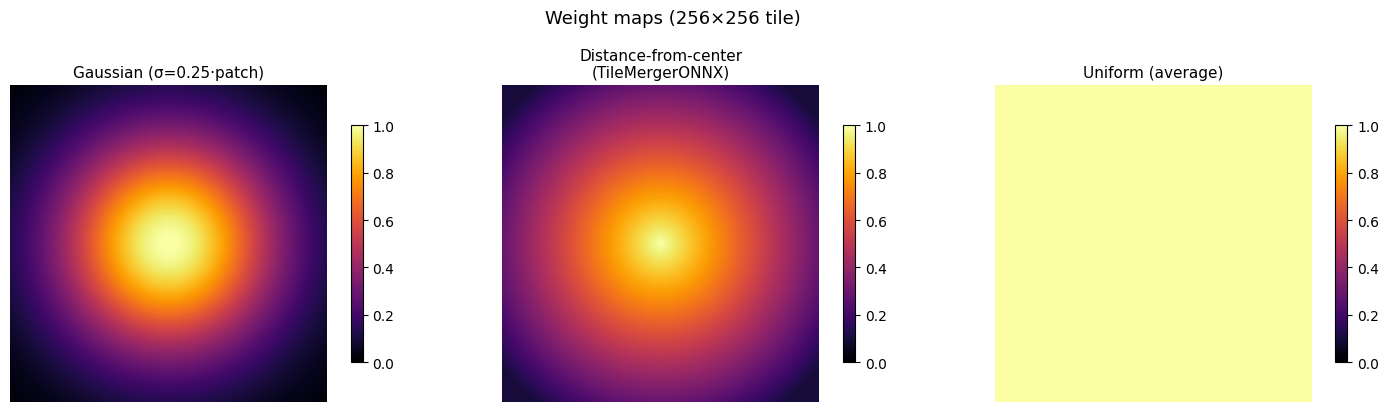

In [110]:
plot_weight_maps()

In [111]:
#| export
def compare_binary_mask_merge(
    soft_tiles: Union[Tensor, np.ndarray],  # Predicted tiles from model. (N, 1, tile_size, tile_size) or (N, tile_size, tile_size). Accepts numpy (ONNX) or torch.
    tile_size: int = 256,  # Tile side length.
    overlap: int = 64,  # Overlap between tiles.
    input_h: int = 480,  # Original image height.
    input_w: int = 480,  # Original image width.
    gt_mask: Optional[Union[Tensor, np.ndarray]] = None,  # Optional ground truth (H, W) for IoU.
    confidence_threshold: float = 0.5,  # Binarization threshold.
    sigma_factor: float = 0.25,  # Gaussian spread for ``gaussian_weighted`` (sigma = sigma_factor * tile_size).
    figsize: tuple = (20, 5),  # Figure size.
) -> dict:
    """Compare merge strategies (per expert panel). ONNX-friendly: accepts numpy or torch.

    Normalizes input from ONNX models (numpy, various shapes) to ``(N, 1, tile_size, tile_size)``
    float32 tensor. Uses only TileMergerONNX (opset 12 compatible) for merging.

    Shows side-by-side merged results.  If *gt_mask* is provided, computes
    IoU for each strategy so you can pick the best one for your data.

    Expert ranking: 1=confidence_weighted, 2=gaussian_weighted, 3=average, 4=overwrite.

    Returns:
        Dict mapping strategy name to merged tensor ``(1, 1, H, W)``.

    Example::

        # From ONNX model: tiles may be numpy (N, 1, 256, 256)
        results = compare_binary_mask_merge(
            soft_tiles=onnx_tiles,
            tile_size=256, overlap=64,
            input_h=480, input_w=480,
            gt_mask=ground_truth_tensor,
        )
    """
    import matplotlib.pyplot as plt

    # ONNX-friendly input normalization: numpy/torch -> (N, 1, tile_size, tile_size) float32
    if isinstance(soft_tiles, np.ndarray):
        soft_tiles = torch.from_numpy(soft_tiles).float()
    else:
        soft_tiles = soft_tiles.detach().float()
    if soft_tiles.ndim == 3:
        soft_tiles = soft_tiles.unsqueeze(1)
    soft_tiles = soft_tiles.to(dtype=torch.float32)

    if gt_mask is not None:
        if isinstance(gt_mask, np.ndarray):
            gt_mask = torch.from_numpy(gt_mask).float()
        else:
            gt_mask = gt_mask.detach().float()

    cfgs = [
        ("overwrite",             dict(merge_strategy="overwrite",             apply_postprocessing=False)),
        ("gaussian_weighted",     dict(merge_strategy="gaussian_weighted",   apply_postprocessing=False)),
        ("gauss_weighted+morph",  dict(merge_strategy="gaussian_weighted",   apply_postprocessing=True)),
        ("confidence_weighted",   dict(merge_strategy="confidence_weighted", apply_postprocessing=False)),
        ("conf_weighted+morph",   dict(merge_strategy="confidence_weighted", apply_postprocessing=True)),
    ]

    results = {}
    n_plots = len(cfgs) + (1 if gt_mask is not None else 0)
    fig, axes = plt.subplots(1, n_plots, figsize=figsize)
    if n_plots == 1: axes = [axes]

    col = 0
    if gt_mask is not None:
        gt_np = gt_mask.cpu().numpy() if gt_mask.ndim == 2 else gt_mask.squeeze().cpu().numpy()
        axes[col].imshow(gt_np, cmap="gray", vmin=0, vmax=1)
        axes[col].set_title("Ground truth", fontsize=11)
        axes[col].axis("off")
        col += 1

    for label, kwargs in cfgs:
        merger = TileMergerONNX(
            tile_size=tile_size, overlap=overlap,
            input_h=input_h, input_w=input_w,
            confidence_threshold=confidence_threshold,
            sigma_factor=sigma_factor, **kwargs)
        merged = merger(soft_tiles)
        results[label] = merged

        title = label
        if gt_mask is not None:
            gt_flat = gt_mask.float() if gt_mask.ndim == 2 else gt_mask.squeeze().float()
            merged_bin = (merged[0, 0] > confidence_threshold).float()
            inter = (merged_bin.cpu() * gt_flat.cpu()).sum()
            union = ((merged_bin.cpu() + gt_flat.cpu()) > 0).float().sum()
            iou = (inter / union).item() if union > 0 else 0.0
            title += f"\nIoU={iou:.4f}"

        axes[col].imshow(merged[0, 0].detach().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        axes[col].set_title(title, fontsize=10)
        axes[col].axis("off")
        col += 1

    fig.suptitle("Binary mask merge strategy comparison", fontsize=13, y=1.02)
    fig.tight_layout()
    plt.show()
    return results


In [114]:
tiles.shape

torch.Size([40, 1, 256, 256])

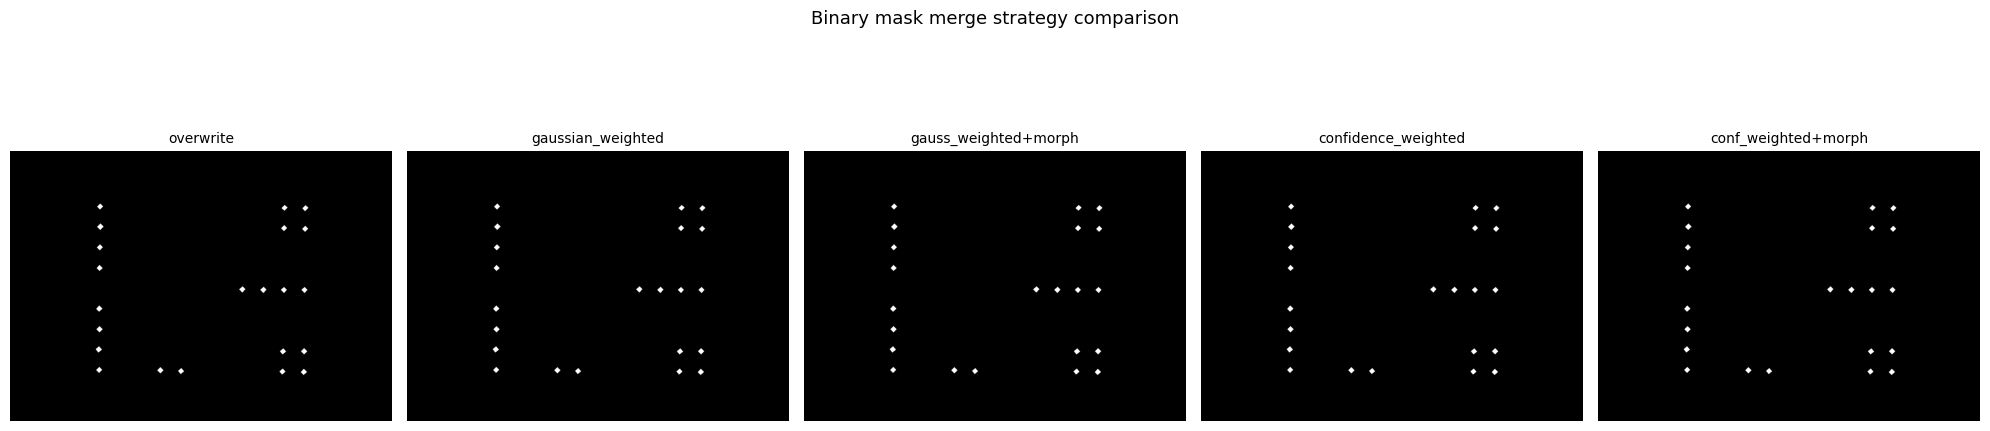

In [116]:
tiles_ = compare_binary_mask_merge(
    soft_tiles=tiles,
    tile_size=256,
    overlap=32,
    input_h=1152,
    input_w=1632,
)

torch.Size([1, 256, 256])

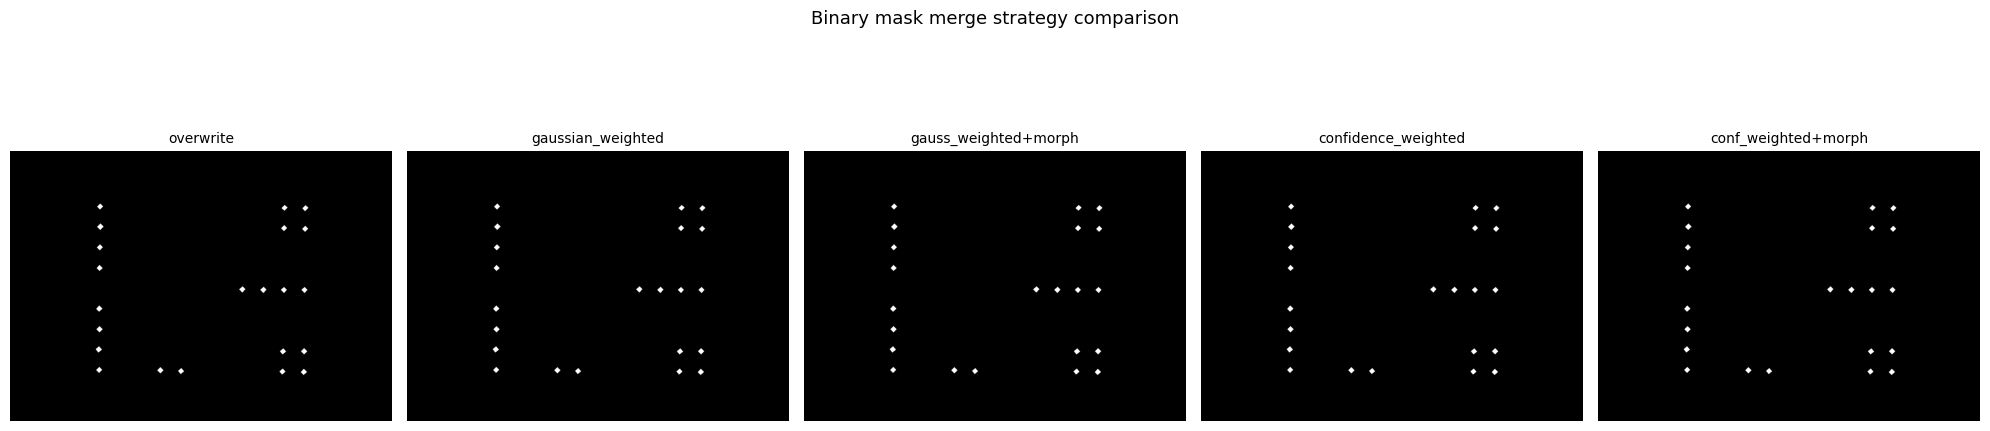

In [121]:
tiles_ = compare_binary_mask_merge(
    soft_tiles=tiles,
    tile_size=256,
    overlap=32,
    input_h=1152,
    input_w=1632,
)

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()